# Importing the required modules

In [1]:
# Modules used for data handling and visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
import random as r
sns.set_style("whitegrid")

# Modules used for suppressing warnings
import warnings 
warnings.filterwarnings('ignore')

# Modules used for dataset split
# import splitfolders
import os

# Modules used for model training and transfer learning
import tensorflow as tf
from tensorflow.keras.layers import Dense,Flatten
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications.resnet50 import ResNet50
from tensorflow.keras import Model

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


# Dataset Exploration

In [3]:
class Dataset:

    def __init__(self, dataset_path: str):
        self.PARENT = dataset_path
        self.class_distribution = dict()
    
    def __compute_class_distributions(self):
        for dirname in os.listdir(self.PARENT):
            self.class_distribution[dirname] = len(os.listdir(os.path.join(self.PARENT, dirname)))

    def class_distributions(self):
        self.__compute_class_distributions()

        plt.figure(figsize=(10,10))
        plt.bar(self.class_distribution.keys(),
                self.class_distribution.values(),
                color=["crimson","red","orange","yellow"])
        plt.xticks(rotation=90)
        plt.title("Class Distribution of PlantVillage dataset")
        plt.xlabel("Class Label")
        plt.ylabel("Frequency of class")
        plt.show()

    def show_class_samples(self):
        rows = 5
        columns = 3
        c = 0
        fig, axs = plt.subplots(rows, columns, figsize=(15,15))
        for dirname in os.listdir(self.PARENT):
            img_path = r.choice(os.listdir(os.path.join(self.PARENT, dirname)))
            image = mpimg.imread(os.path.join(self.PARENT, dirname, img_path))
            axs[c//columns, c%columns].imshow(image)
            axs[c//columns, c%columns].set_title(dirname)
            c += 1
        fig.suptitle("Image Samples of Plant Village dataset")
        plt.subplots_adjust(bottom=0.1, top=0.9, hspace=0.5)
        plt.show()


## Loading the dataset

In [4]:
plant_village = Dataset("/kaggle/input/plant-village-dataset/PlantVillageDataset/PlantVillage/PlantVillage")

## Class Distribution

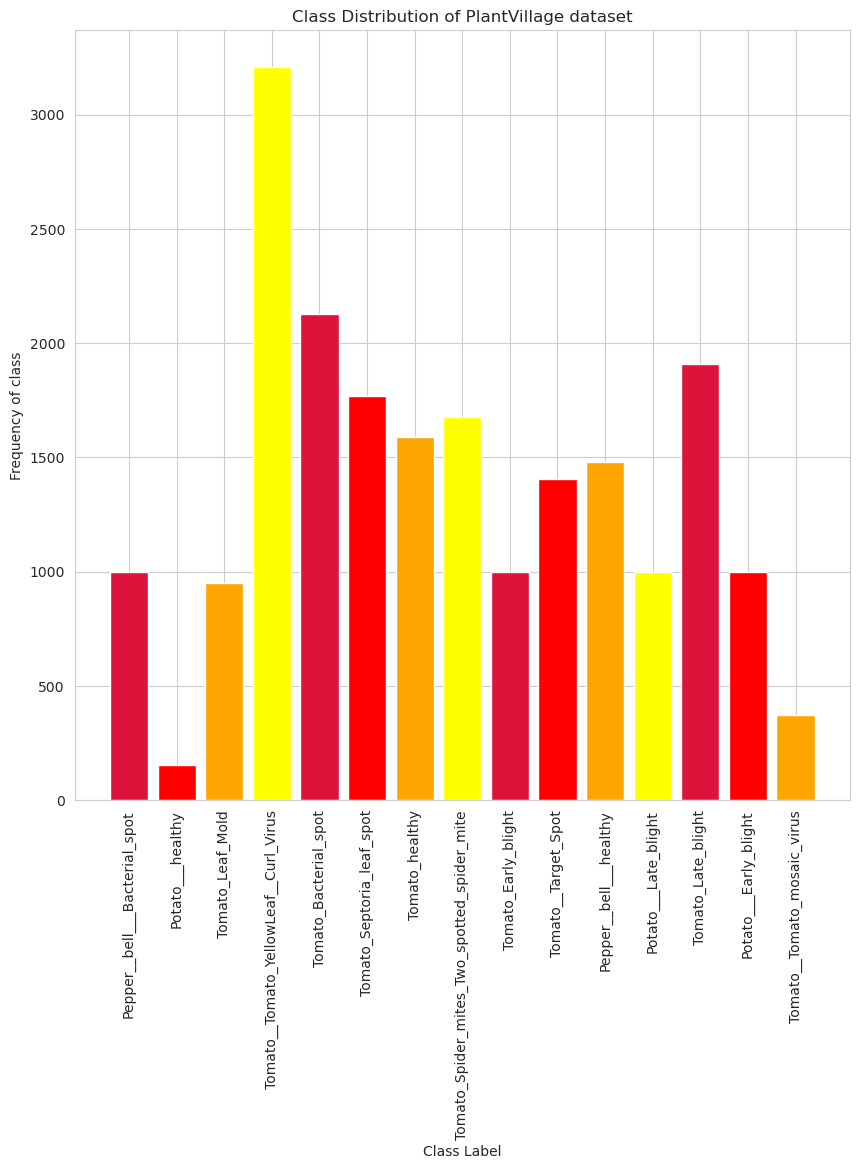

In [5]:
plant_village.class_distributions()

## Sample Images

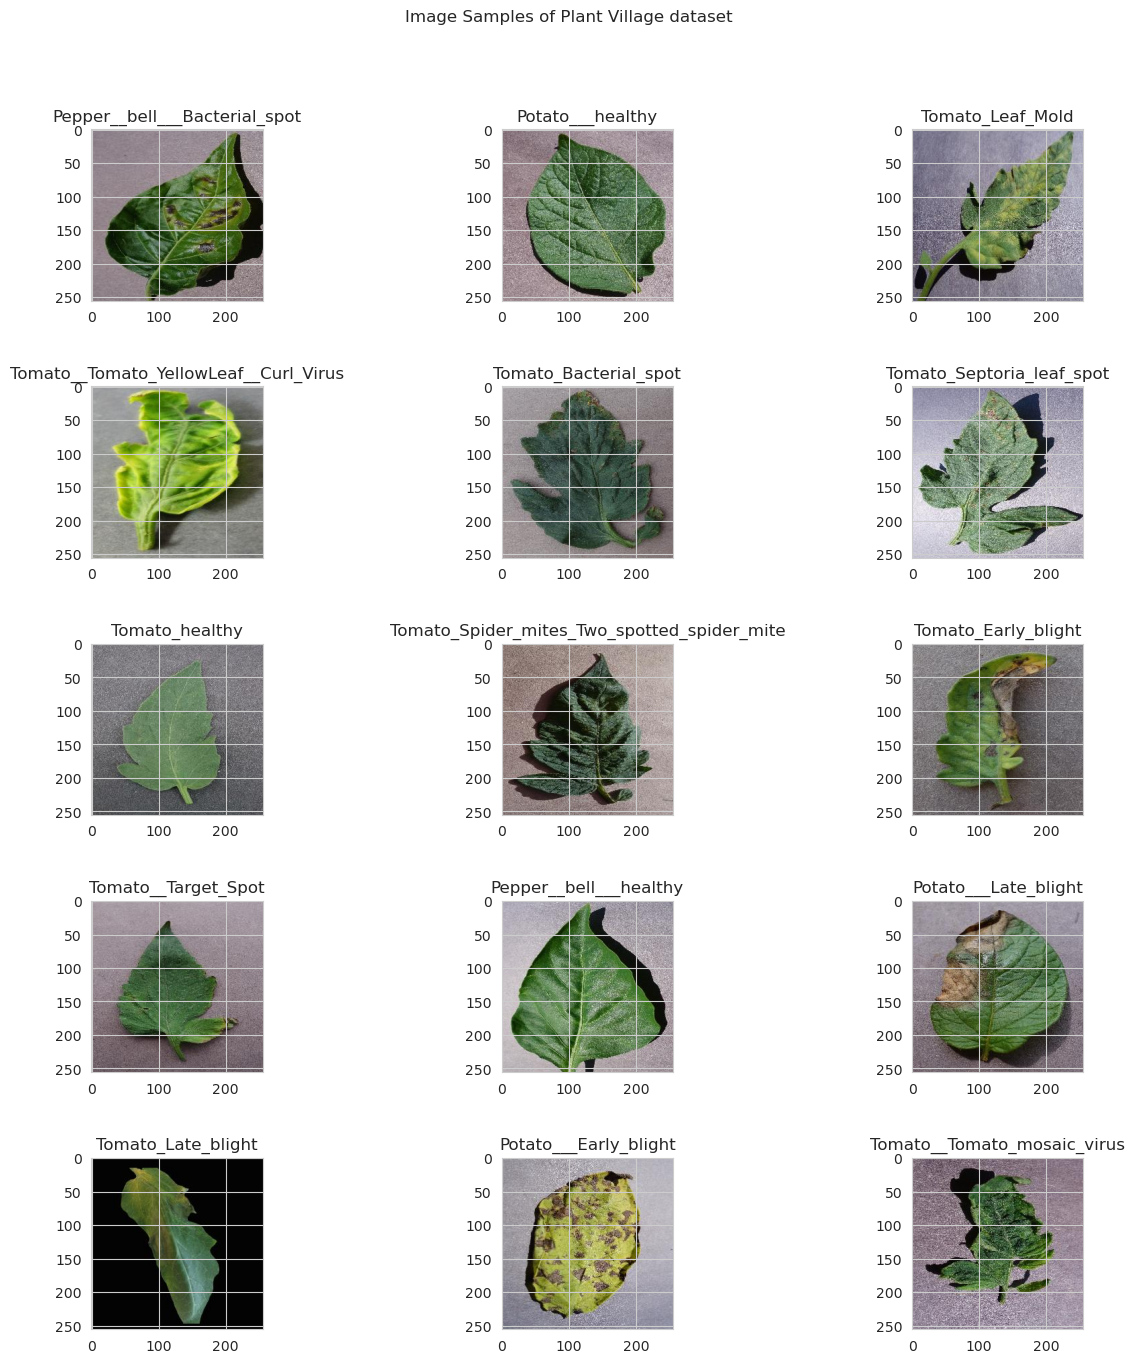

In [6]:
plant_village.show_class_samples()

# Train, Test, Validation Split

In [7]:

class DataSplit:

    def __init__(self, dataset_path: str, train_path: str, test_path: str, val_path: str) -> None:
        self.PARENT = dataset_path
        self.TRAIN_DIR = train_path
        self.TEST_DIR = test_path
        self.VAL_DIR = val_path
        self.train_gen = None
        self.test_gen = None
        self.val_gen = None

    def create_generators(self):
        self.train_gen = tf.keras.preprocessing.image.ImageDataGenerator(
            preprocessing_function=tf.keras.applications.resnet50.preprocess_input,
        )

        self.test_gen = tf.keras.preprocessing.image.ImageDataGenerator(
            preprocessing_function=tf.keras.applications.resnet50.preprocess_input
        )

        self.val_gen =  tf.keras.preprocessing.image.ImageDataGenerator(
            preprocessing_function=tf.keras.applications.resnet50.preprocess_input
        )

    def get_images(self):
        train_images = self.train_gen.flow_from_directory(
            directory=self.TRAIN_DIR,
            target_size=(75, 75),
            color_mode='rgb',
            class_mode='categorical',
            batch_size=32,
            shuffle=True,
            seed=42,
            subset='training'
        )

        val_images = self.val_gen.flow_from_directory(
            directory=self.VAL_DIR,
            target_size=(75, 75),
            color_mode='rgb',
            class_mode='categorical',
            batch_size=32,
            shuffle=True,
            seed=42
        )

        test_images = self.test_gen.flow_from_directory(
            directory=self.TEST_DIR,
            target_size=(75, 75),
            color_mode='rgb',
            class_mode='categorical',
            batch_size=32,
            shuffle=False,
            seed=42
        )

        return train_images, val_images, test_images


In [8]:

ds = DataSplit("PlantVillage", "/kaggle/input/plant-village-dataset/PlantVillageDataset/train_val_test/train", "/kaggle/input/plant-village-dataset/PlantVillageDataset/train_val_test/test", "/kaggle/input/plant-village-dataset/PlantVillageDataset/train_val_test/val")


## Train Data Insights

In [10]:
train = Dataset("/kaggle/input/plant-village-dataset/PlantVillageDataset/train_val_test/train")

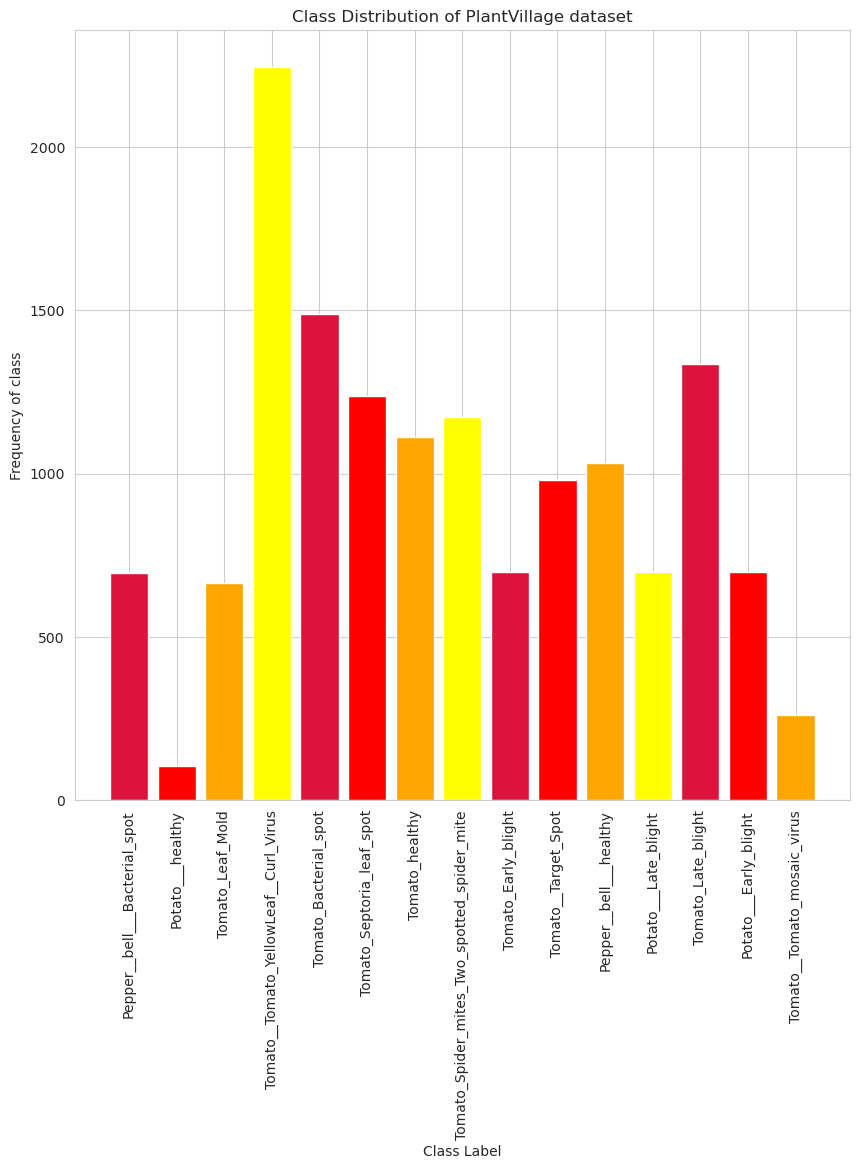

In [11]:
train.class_distributions()

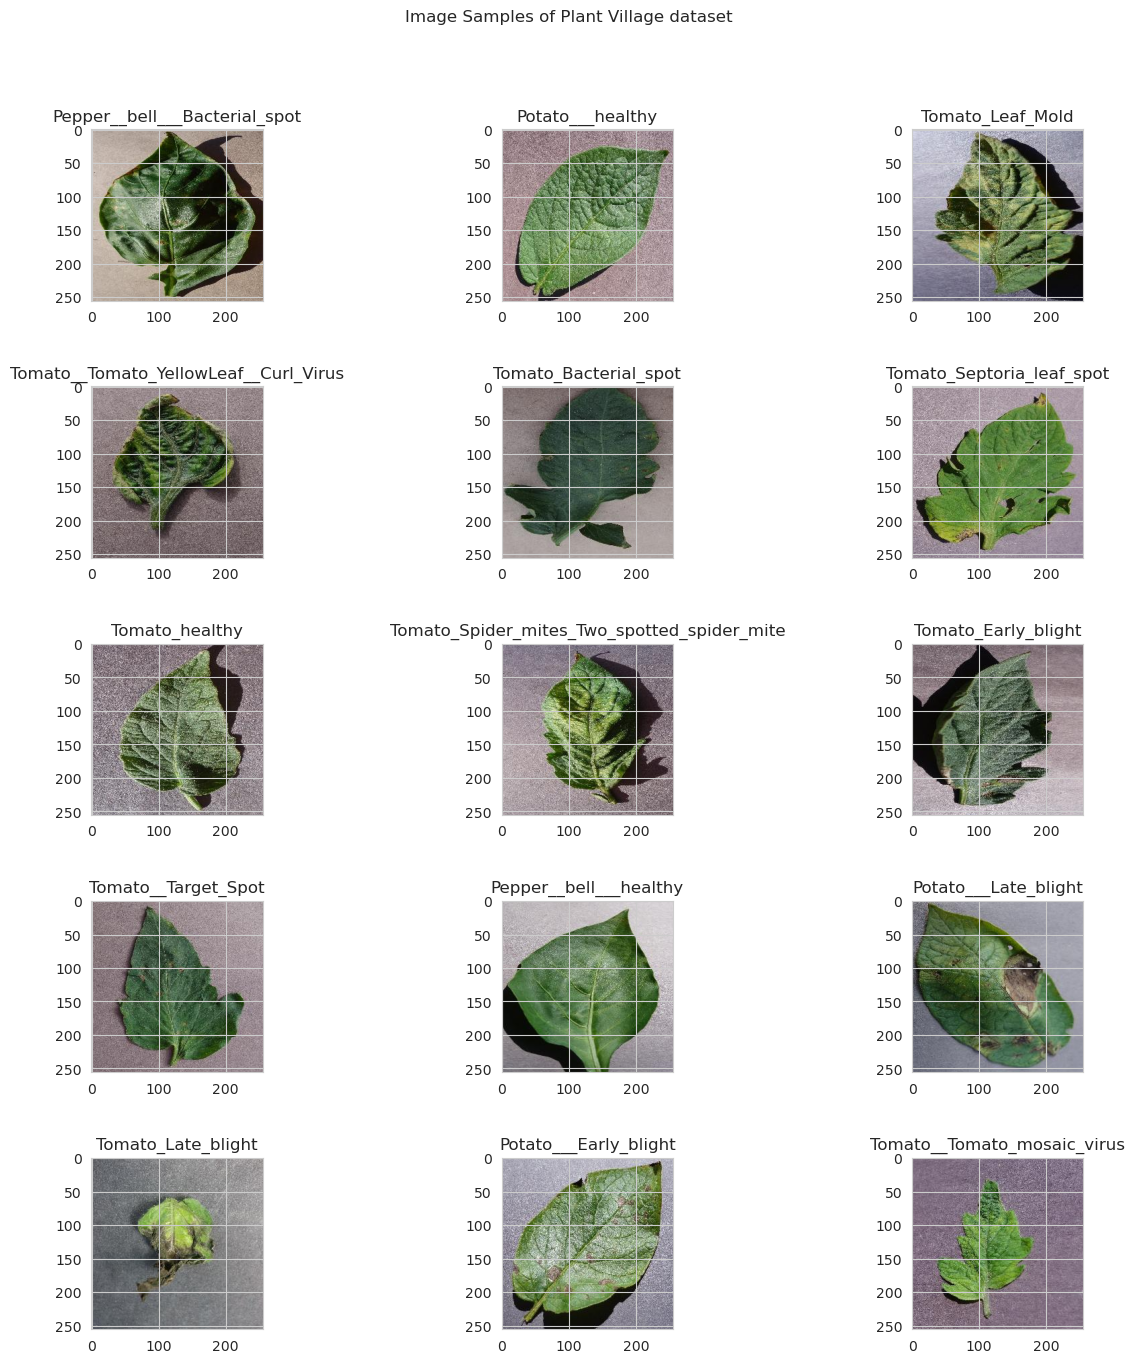

In [12]:
train.show_class_samples()

## Test Data Insights

In [13]:
test = Dataset("/kaggle/input/plant-village-dataset/PlantVillageDataset/train_val_test/test/")

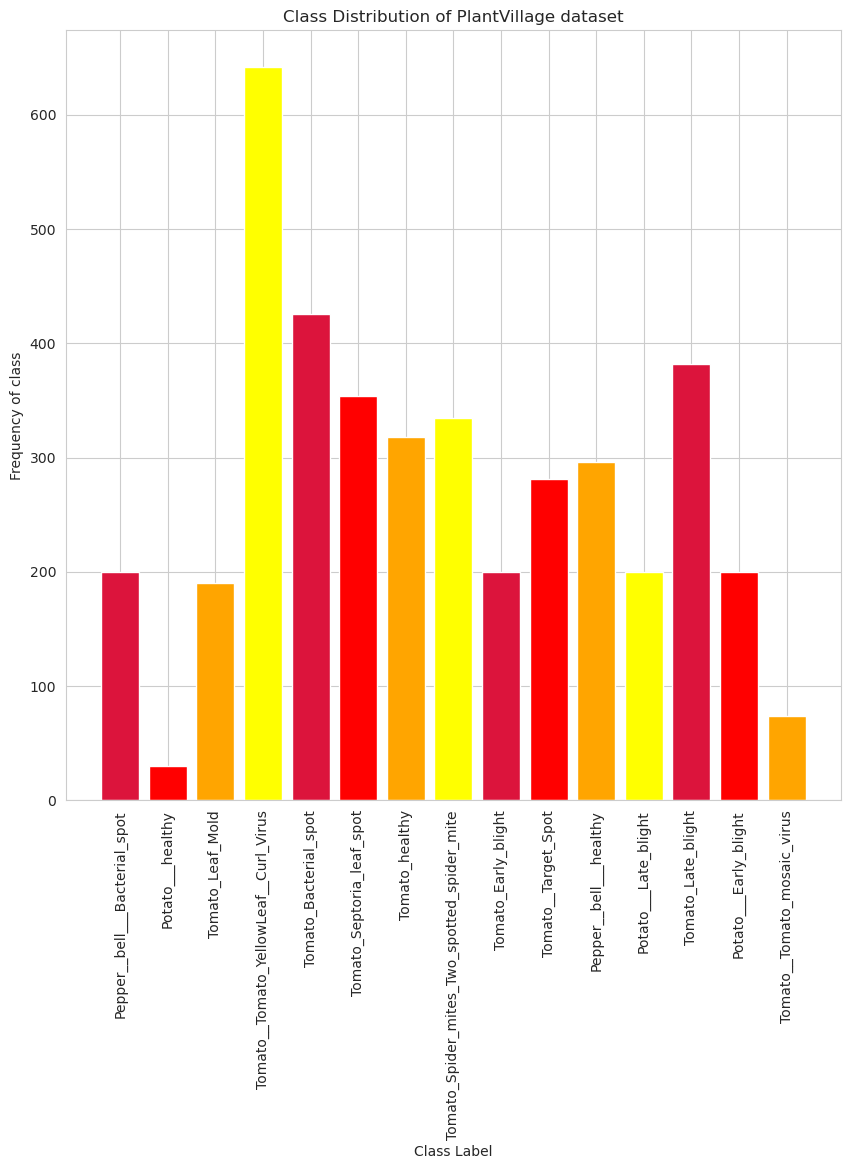

In [14]:
test.class_distributions()

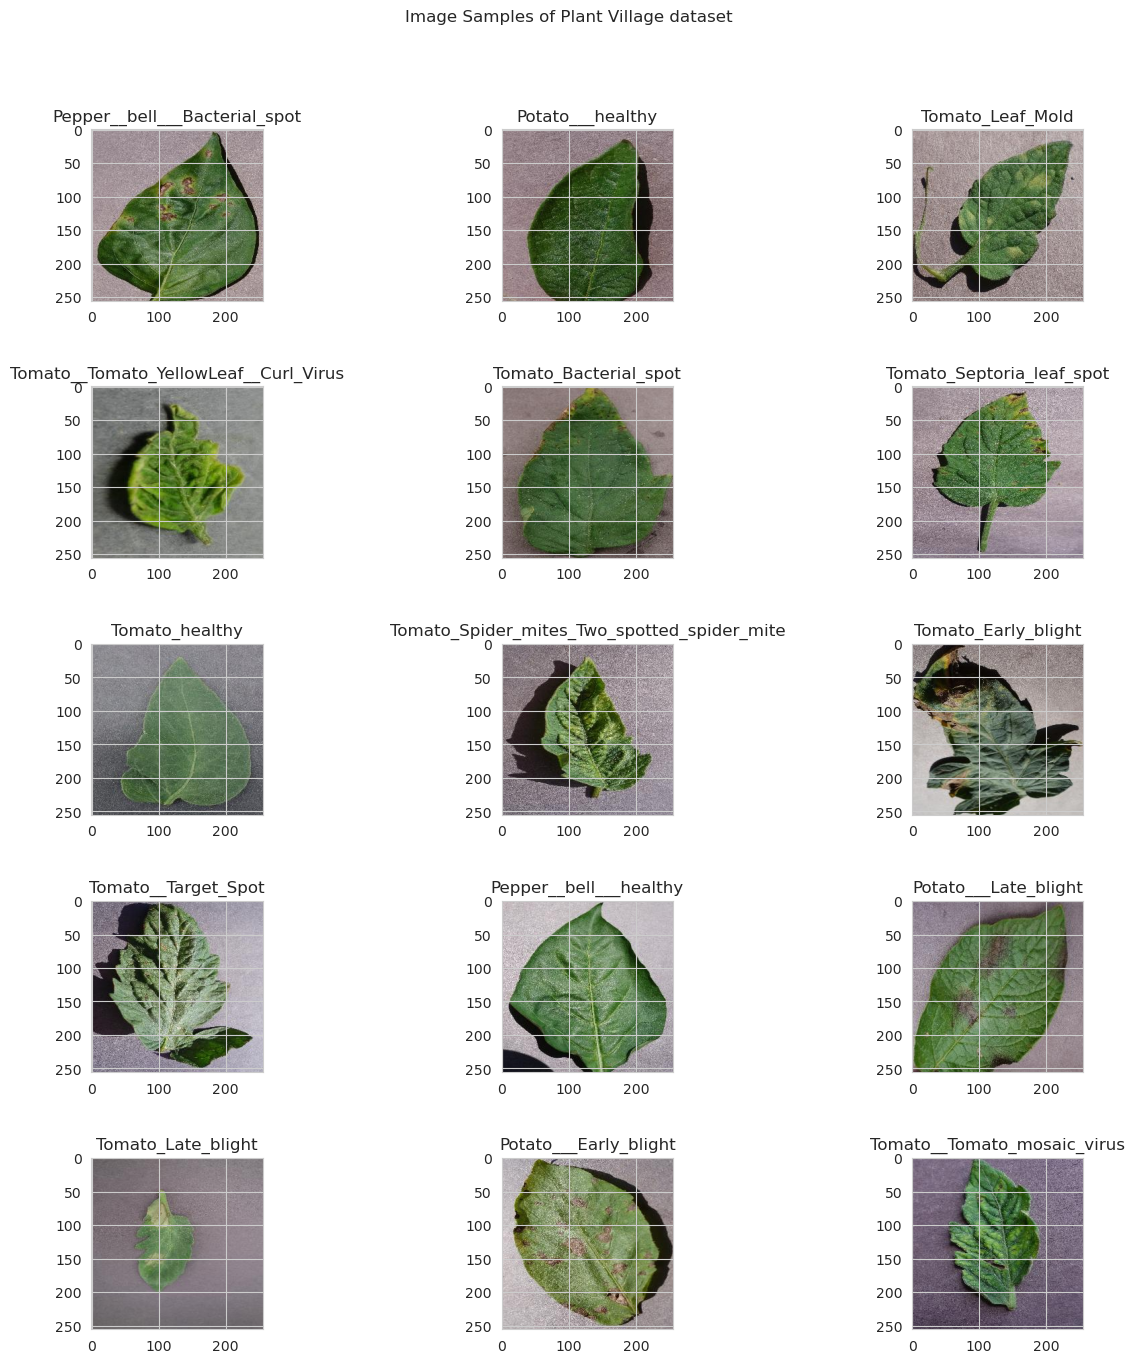

In [15]:
test.show_class_samples()

## Validation Data Insights

In [16]:
val = Dataset("/kaggle/input/plant-village-dataset/PlantVillageDataset/train_val_test/val/")

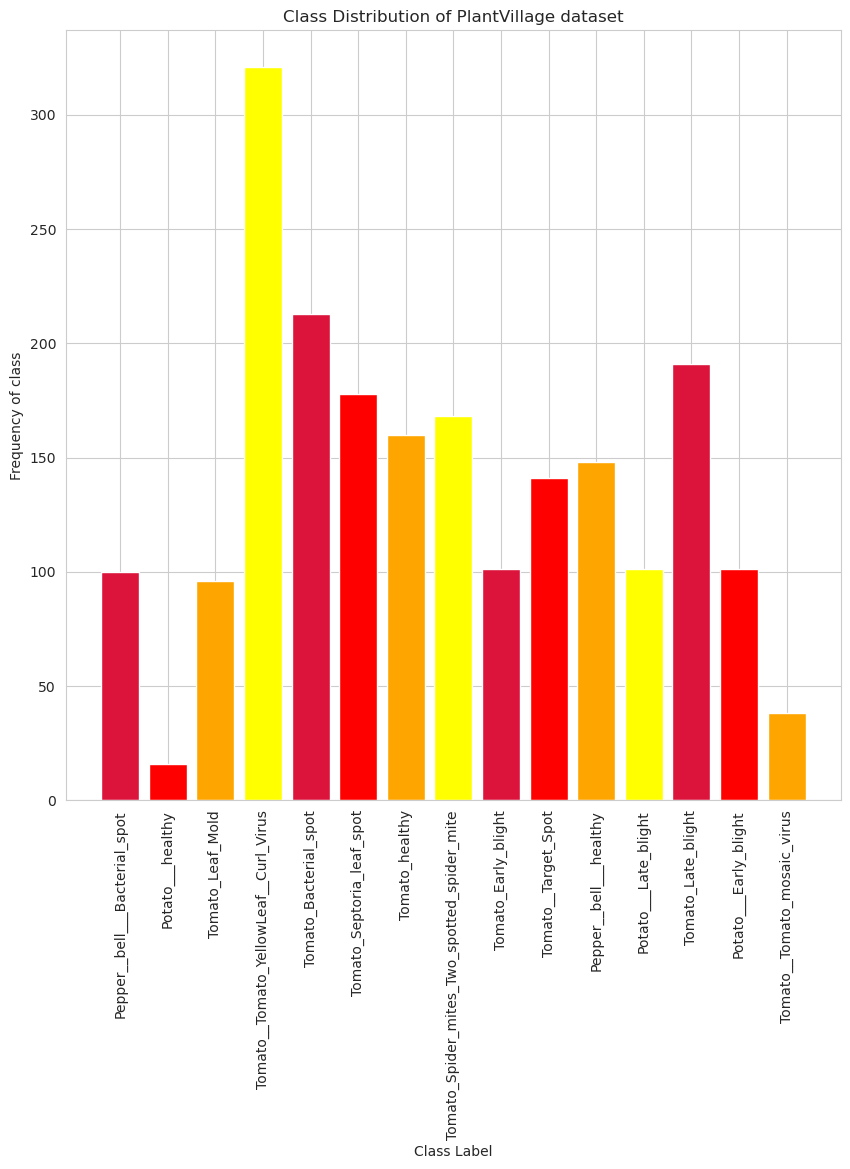

In [17]:
val.class_distributions()

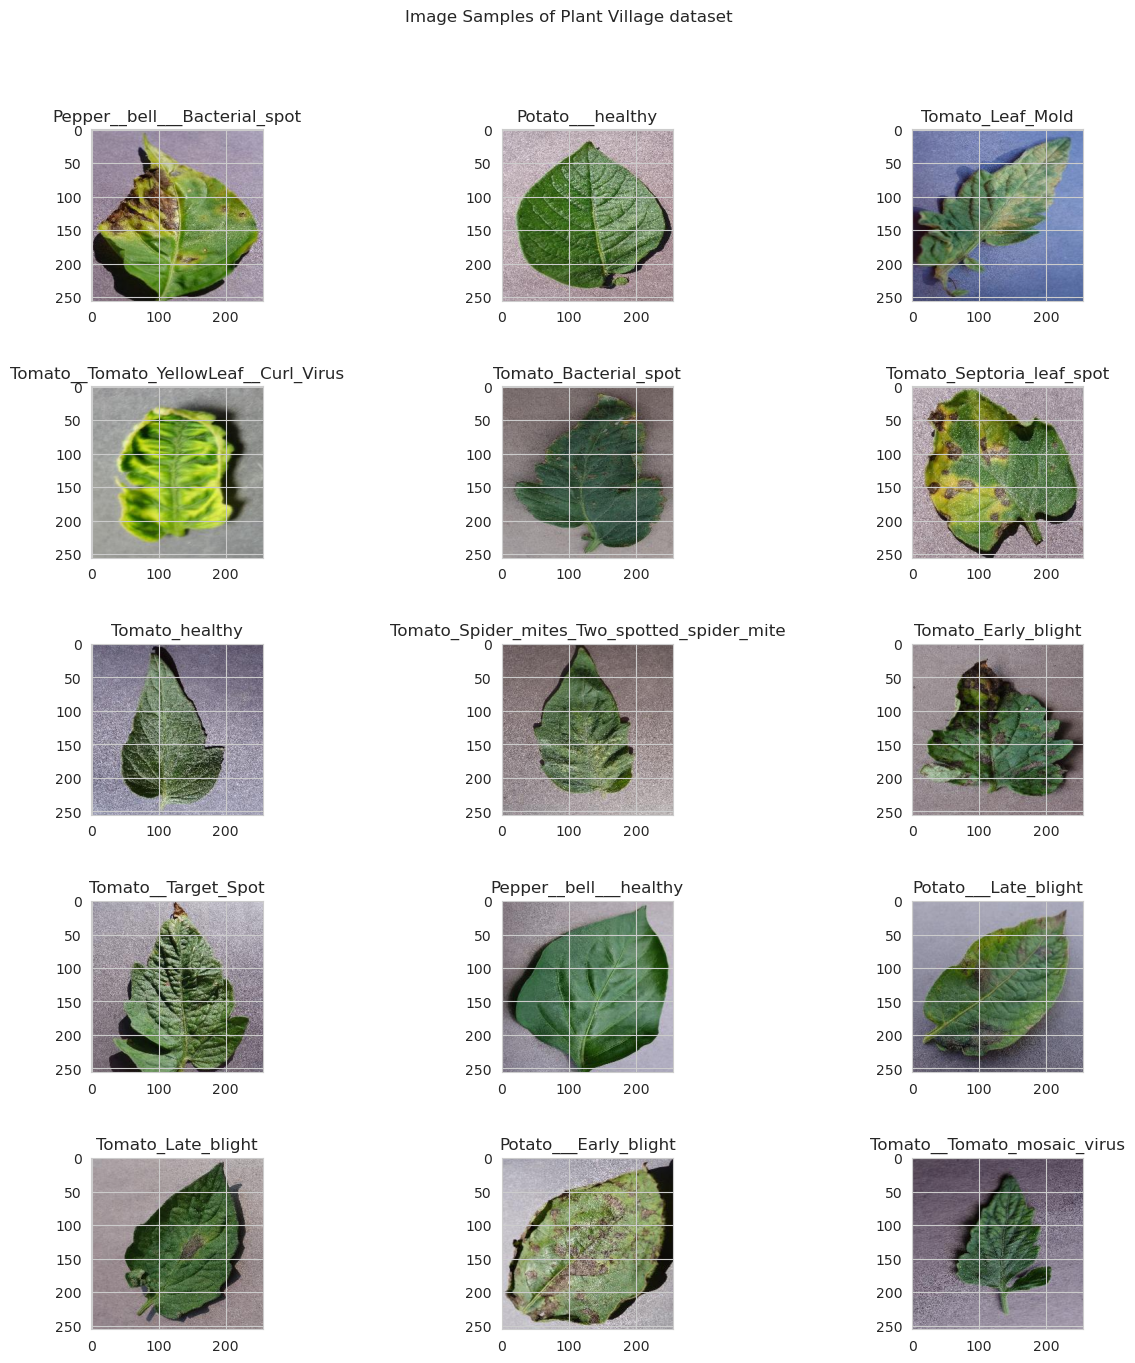

In [18]:
val.show_class_samples()

## Creating the data generators

In [19]:
ds.create_generators()

In [20]:
train, val, test = ds.get_images()

Found 14437 images belonging to 15 classes.
Found 2073 images belonging to 15 classes.
Found 4128 images belonging to 15 classes.


# Transfer Learning

In [21]:
class TransferLearning:

    def __init__(self, train, val) -> None:
        self.train = train
        self.val = val
        self.model = None
        self.history = None

    def load_model(self):
        self.model = ResNet50(weights = 'imagenet', 
                              include_top = False, 
                              input_shape = (75,75,3))
    
    def mark_layers_non_trainable(self):
        for layer in self.model.layers:
            layer.trainable = False
    
    def add_final_layer(self):
        self.x = Flatten()(self.model.output)
        self.x = Dense(1000, activation='relu')(self.x)
        self.predictions = Dense(15, activation = 'softmax')(self.x)

    def compile_model(self):
        self.model = Model(inputs = self.model.input, outputs = self.predictions)
        self.model.compile(optimizer='adam', loss="categorical_crossentropy", metrics=['accuracy'])
    
    def train_model(self):
        self.history = self.model.fit(train,
                                      batch_size=32, 
                                      epochs=50, validation_data=val)
    
    def plot_history(self):
        fig, axs = plt.subplots(2, 1, figsize=(15,15))
        axs[0].plot(self.history.history['loss'])
        axs[0].plot(self.history.history['val_loss'])
        axs[0].title.set_text('Training Loss vs Validation Loss')
        axs[0].set_xlabel('Epochs')
        axs[0].set_ylabel('Loss')
        axs[0].legend(['Train','Val'])

        axs[1].plot(self.history.history['accuracy'])
        axs[1].plot(self.history.history['val_accuracy'])
        axs[1].title.set_text('Training Accuracy vs Validation Accuracy')
        axs[1].set_xlabel('Epochs')
        axs[1].set_ylabel('Accuracy')
        axs[1].legend(['Train', 'Val'])

## Transfer Learning using Resnet50

In [22]:
tl = TransferLearning(train=train, val=val)

## Loading the Resnet50 from Keras Application

In [23]:
tl.load_model()

94765736/94765736 [==============================] - 0s 0us/step


## Making all the layers of the model non-trainable

In [24]:
tl.mark_layers_non_trainable()

## Adding a final layer for classification of 15 classes

In [25]:
tl.add_final_layer()

## Compiling model

In [26]:
tl.compile_model()

## Training model

In [27]:
tl.train_model()

Epoch 1/50
452/452 [==============================] - 197s 419ms/step - loss: 1.8722 - accuracy: 0.7927 - val_loss: 0.3698 - val_accuracy: 0.8833
Epoch 2/50
452/452 [==============================] - 60s 133ms/step - loss: 0.2171 - accuracy: 0.9274 - val_loss: 0.4049 - val_accuracy: 0.8895
Epoch 3/50
452/452 [==============================] - 36s 79ms/step - loss: 0.1344 - accuracy: 0.9547 - val_loss: 0.4980 - val_accuracy: 0.8731
Epoch 4/50
452/452 [==============================] - 40s 88ms/step - loss: 0.1074 - accuracy: 0.9644 - val_loss: 0.3993 - val_accuracy: 0.9074
Epoch 5/50
452/452 [==============================] - 36s 79ms/step - loss: 0.1098 - accuracy: 0.9654 - val_loss: 0.5700 - val_accuracy: 0.8813
Epoch 6/50
452/452 [==============================] - 37s 83ms/step - loss: 0.1048 - accuracy: 0.9672 - val_loss: 0.4283 - val_accuracy: 0.8963
Epoch 7/50
452/452 [==============================] - 39s 86ms/step - loss: 0.0868 - accuracy: 0.9742 - val_loss: 0.5163 - val_accura

In [28]:
tl.model.save("models/first_model.h5")

In [29]:
CLASS_NAMES = list(train.class_indices.keys())
CLASS_NAMES

['Pepper__bell___Bacterial_spot',
 'Pepper__bell___healthy',
 'Potato___Early_blight',
 'Potato___Late_blight',
 'Potato___healthy',
 'Tomato_Bacterial_spot',
 'Tomato_Early_blight',
 'Tomato_Late_blight',
 'Tomato_Leaf_Mold',
 'Tomato_Septoria_leaf_spot',
 'Tomato_Spider_mites_Two_spotted_spider_mite',
 'Tomato__Target_Spot',
 'Tomato__Tomato_YellowLeaf__Curl_Virus',
 'Tomato__Tomato_mosaic_virus',
 'Tomato_healthy']

In [30]:
from sklearn.metrics import accuracy_score, classification_report

In [31]:
predictions = np.argmax(tl.model.predict(test), axis=1)

129/129 [==============================] - 49s 375ms/step


Test Accuracy: 92.175%


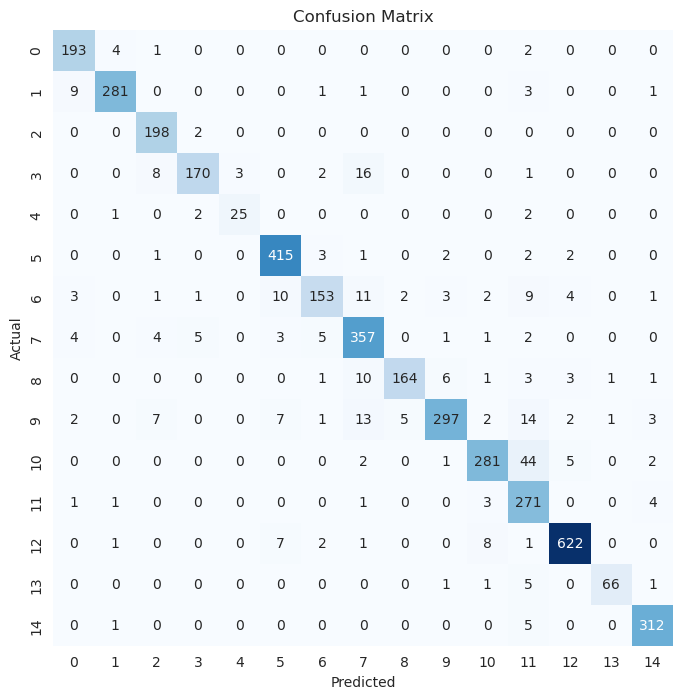

In [32]:
acc = accuracy_score(test.labels, predictions)
cm = tf.math.confusion_matrix(test.labels, predictions)
clr = classification_report(test.labels, predictions, target_names=CLASS_NAMES)

print("Test Accuracy: {:.3f}%".format(acc * 100))

plt.figure(figsize=(8, 8))
sns.heatmap(cm, annot=True, fmt='g', vmin=0, cmap='Blues', cbar=False)
# plt.xticks(ticks= np.arange(15) + 0.5, labels=CLASS_NAMES, rotation=90)
# plt.yticks(ticks= np.arange(15) + 0.5, labels=CLASS_NAMES, rotation=0)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [33]:
print(clr)

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.91      0.96      0.94       200
                     Pepper__bell___healthy       0.97      0.95      0.96       296
                      Potato___Early_blight       0.90      0.99      0.94       200
                       Potato___Late_blight       0.94      0.85      0.89       200
                           Potato___healthy       0.89      0.83      0.86        30
                      Tomato_Bacterial_spot       0.94      0.97      0.96       426
                        Tomato_Early_blight       0.91      0.77      0.83       200
                         Tomato_Late_blight       0.86      0.93      0.90       382
                           Tomato_Leaf_Mold       0.96      0.86      0.91       190
                  Tomato_Septoria_leaf_spot       0.95      0.84      0.89       354
Tomato_Spider_mites_Two_spotted_spider_mite       0.94      0.84

## Plotting the Learning Curves

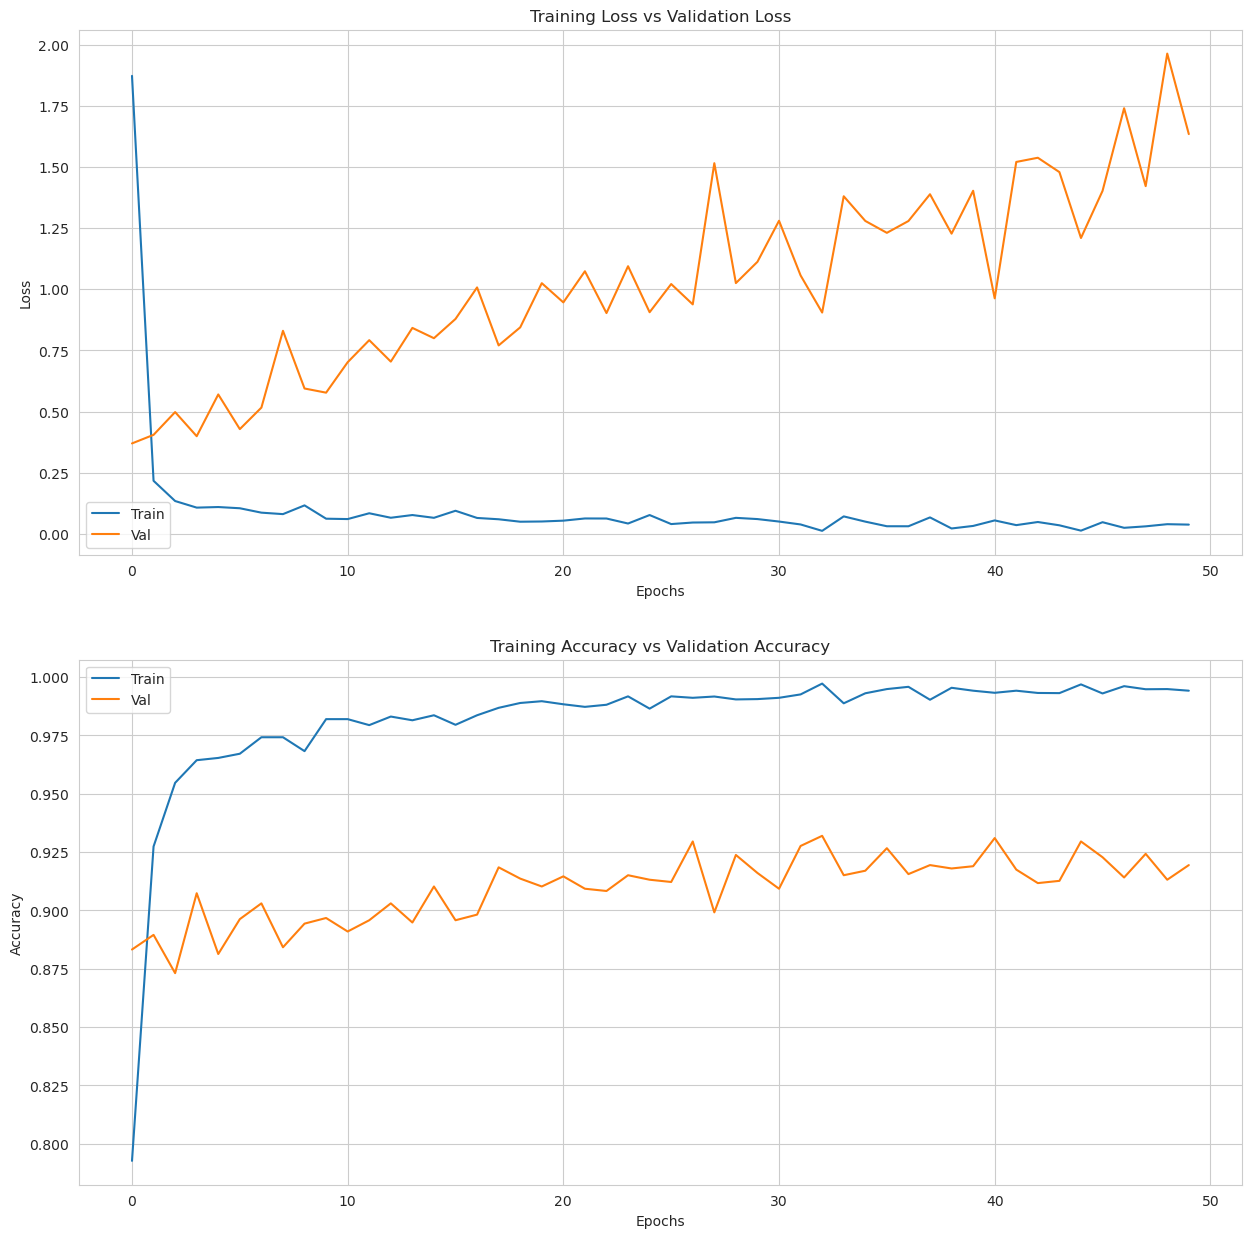

In [34]:
tl.plot_history()

# Fine-tuning

In [35]:
class FineTuning:

    def __init__(self, train, val) -> None:
        self.train = train
        self.val = val
        self.model = None
        self.history = None
        self.fine_tune_from = 100

    def load_model(self):
        self.model = ResNet50(weights = 'imagenet', 
                              include_top = False, 
                              input_shape = (75,75,3))
    
    def fine_tune(self):
        for layer in self.model.layers[:self.fine_tune_from]:
            layer.trainable = False

        for layer in self.model.layers[self.fine_tune_from:]:
            layer.trainable = True
    
    def add_final_layer(self):
        self.x = Flatten()(self.model.output)
        self.x = Dense(1000, activation='relu')(self.x)
        self.predictions = Dense(15, activation = 'softmax')(self.x)

    def compile_model(self):
        self.model = Model(inputs = self.model.input, outputs = self.predictions)
        self.model.compile(optimizer='adam', loss="categorical_crossentropy", metrics=['accuracy'])
    
    def train_model(self):
        self.history = self.model.fit(train,
                                      batch_size=32, 
                                      epochs=10, 
                                      validation_data=val,
                                      callbacks=[
                                        tf.keras.callbacks.EarlyStopping(
                                            monitor='val_loss',
                                            patience=3,
                                            restore_best_weights=True
                                        )
                                     ])
    
    def plot_history(self):
        fig, axs = plt.subplots(2, 1, figsize=(15,15))
        axs[0].plot(self.history.history['loss'])
        axs[0].plot(self.history.history['val_loss'])
        axs[0].title.set_text('Training Loss vs Validation Loss')
        axs[0].set_xlabel('Epochs')
        axs[0].set_ylabel('Loss')
        axs[0].legend(['Train','Val'])

        axs[1].plot(self.history.history['accuracy'])
        axs[1].plot(self.history.history['val_accuracy'])
        axs[1].title.set_text('Training Accuracy vs Validation Accuracy')
        axs[1].set_xlabel('Epochs')
        axs[1].set_ylabel('Accuracy')
        axs[1].legend(['Train', 'Val'])

## Fine Tuning the ResNet50 model

In [36]:
ft = FineTuning(train,val)

## Loading the ResNet50 model from keras applications

In [37]:
ft.load_model()

## Making last 75 layers of the ResNet50 model trainable

In [38]:
ft.fine_tune()

## Adding a final layer for classification of 15 classes

In [39]:
ft.add_final_layer()

## Compiling the model

In [40]:
ft.compile_model()

## Training the model for 5 epochs

In [41]:
ft.train_model()

Epoch 1/10
452/452 [==============================] - 48s 65ms/step - loss: 0.7550 - accuracy: 0.8487 - val_loss: 0.4720 - val_accuracy: 0.8871
Epoch 2/10
452/452 [==============================] - 27s 59ms/step - loss: 0.1527 - accuracy: 0.9518 - val_loss: 0.2221 - val_accuracy: 0.9315
Epoch 3/10
452/452 [==============================] - 27s 61ms/step - loss: 0.1838 - accuracy: 0.9681 - val_loss: 2.7312 - val_accuracy: 0.8982
Epoch 4/10
452/452 [==============================] - 33s 73ms/step - loss: 0.1238 - accuracy: 0.9751 - val_loss: 0.8844 - val_accuracy: 0.9088
Epoch 5/10
452/452 [==============================] - 32s 70ms/step - loss: 0.0784 - accuracy: 0.9801 - val_loss: 0.2447 - val_accuracy: 0.9532


In [42]:
ft.model.save("models/second_model.h5")

In [43]:
predictions = np.argmax(ft.model.predict(test), axis=1)

129/129 [==============================] - 11s 77ms/step


Test Accuracy: 93.992%


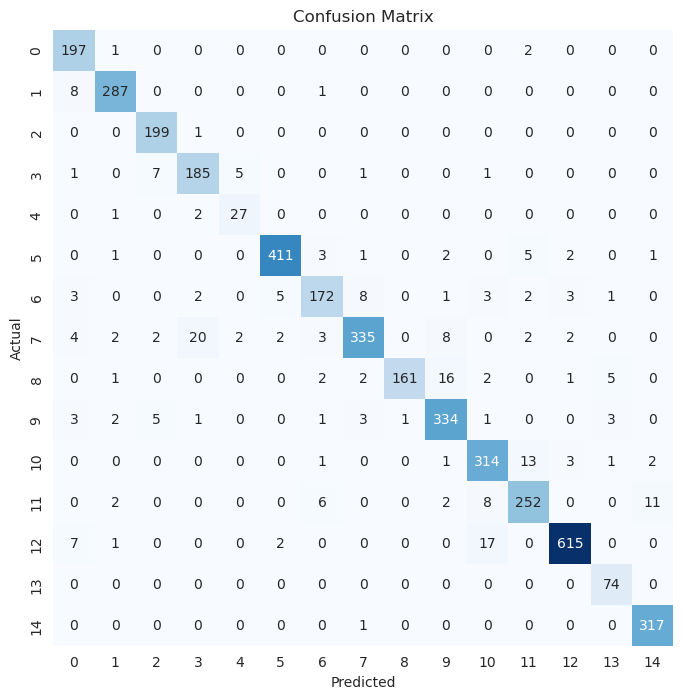

In [44]:
acc = accuracy_score(test.labels, predictions)
cm = tf.math.confusion_matrix(test.labels, predictions)
clr = classification_report(test.labels, predictions, target_names=CLASS_NAMES)

print("Test Accuracy: {:.3f}%".format(acc * 100))

plt.figure(figsize=(8, 8))
sns.heatmap(cm, annot=True, fmt='g', vmin=0, cmap='Blues', cbar=False)
# plt.xticks(ticks= np.arange(15) + 0.5, labels=CLASS_NAMES, rotation=90)
# plt.yticks(ticks= np.arange(15) + 0.5, labels=CLASS_NAMES, rotation=0)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [45]:
print(clr)

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.88      0.98      0.93       200
                     Pepper__bell___healthy       0.96      0.97      0.97       296
                      Potato___Early_blight       0.93      0.99      0.96       200
                       Potato___Late_blight       0.88      0.93      0.90       200
                           Potato___healthy       0.79      0.90      0.84        30
                      Tomato_Bacterial_spot       0.98      0.96      0.97       426
                        Tomato_Early_blight       0.91      0.86      0.88       200
                         Tomato_Late_blight       0.95      0.88      0.91       382
                           Tomato_Leaf_Mold       0.99      0.85      0.91       190
                  Tomato_Septoria_leaf_spot       0.92      0.94      0.93       354
Tomato_Spider_mites_Two_spotted_spider_mite       0.91      0.94

## Evaluation of the fine-tuned model

In [46]:
ft.model.evaluate(test)

129/129 [==============================] - 12s 96ms/step - loss: 0.2688 - accuracy: 0.9399


[0.2687567472457886, 0.9399224519729614]

## Plotting the learning curves of the fine-tuning process

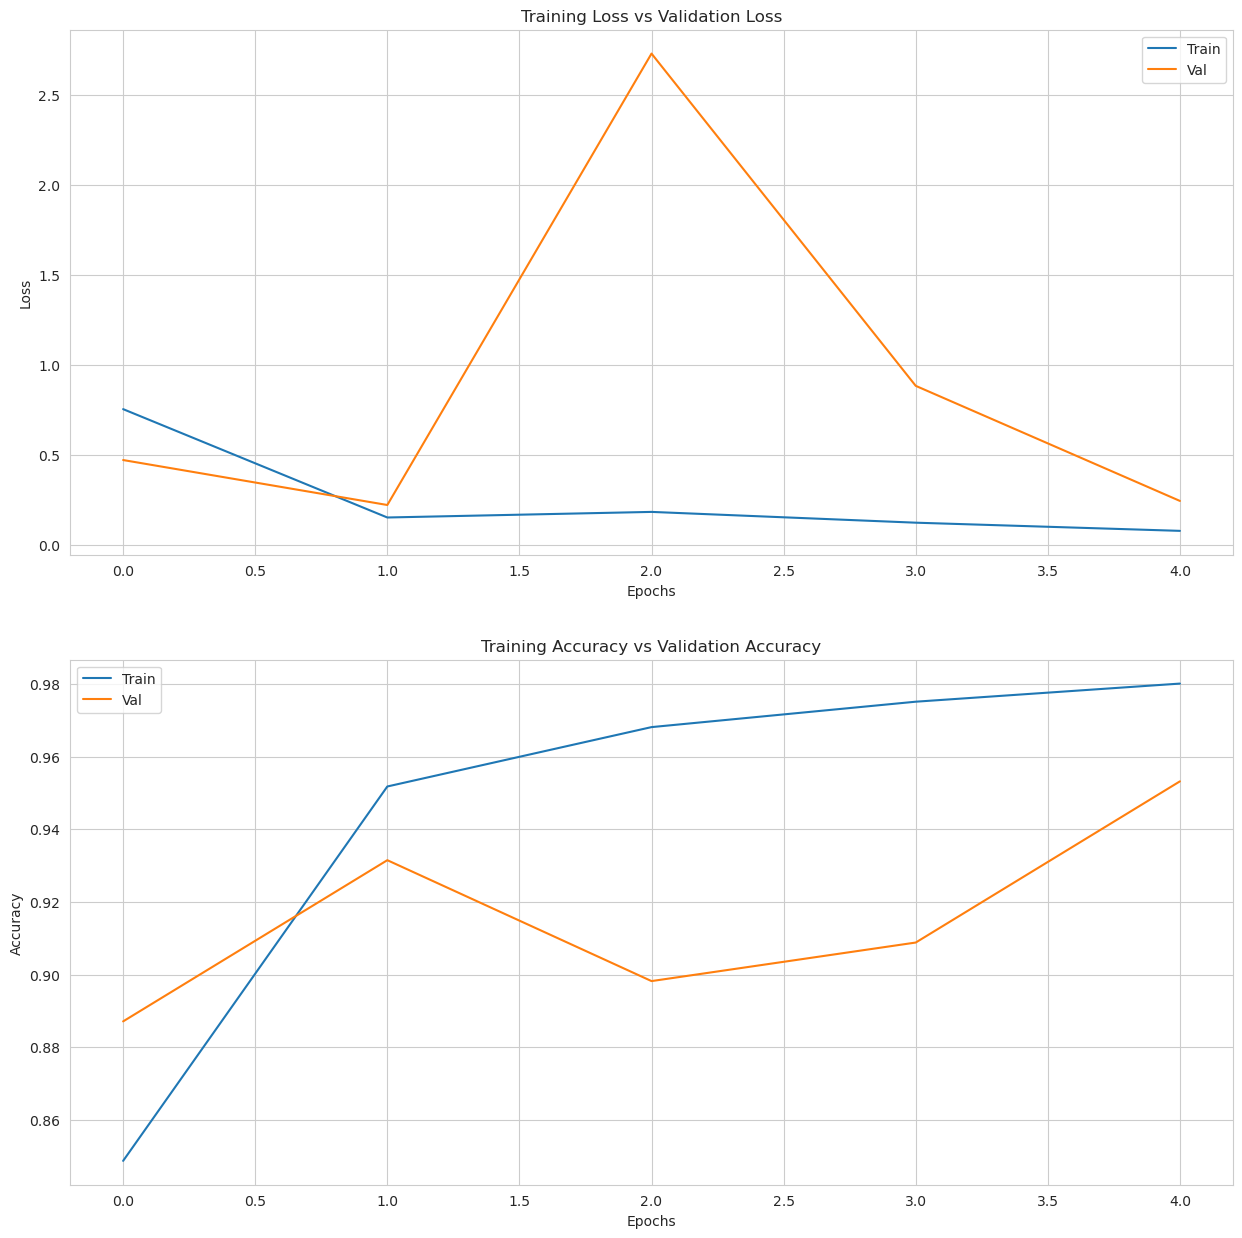

In [47]:
ft.plot_history()

# Conclusion

In [50]:
# Calculate predictions for Fine-Tuning Model
predictions_ft = np.argmax(ft.model.predict(test), axis=1)

# Calculate metrics for Fine-Tuning Model
acc_ft = accuracy_score(test.labels, predictions_ft)
recall_ft = recall_score(test.labels, predictions_ft, average='weighted')
precision_ft = precision_score(test.labels, predictions_ft, average='weighted')
f1_ft = f1_score(test.labels, predictions_ft, average='weighted')



129/129 [==============================] - 7s 52ms/step


In [55]:
print("Accuracy: {:.9f}".format(acc_ft))
print("Precision: {:.9f}".format(precision_ft))
print("Recall: {:.9f}".format(recall_ft))
print("F1-score: {:.9f}".format(f1_ft))


Accuracy: 0.939922481
Precision: 0.941364064
Recall: 0.939922481
F1-score: 0.939786310
